# Clustering Student Learning Profiles

**Machine Learning Techniques (43504) · University of Alicante · 2026–2027**

## 1. Introduction, Team & Hypotheses

**Goal.** Find out whether students who used an online ML learning tool form distinct profiles, and whether those profiles relate to how they did on the exam. Instead of mixing tool use and exam scores into one clustering, the analysis builds **two independent maps of the same students**, one for *how they used the tool* and one for *how they did on the exam*, and then tests whether the two maps agree beyond chance. That turns the vague question "does engagement relate to performance?" into a single falsifiable clustering test.

**Team and workflow.** Marius Botezatu (solo team): exploratory analysis, data preparation, modelling, interpretation and writing. The work is version-controlled on GitHub with small, descriptive commits, and this notebook is the single, self-contained report.

**Hypotheses**

- **H1 · Engagement profiles.** Tool use forms at least three distinct, stable engagement profiles, and they differ not only in *how much* students use the tool but also in their *pace* (minutes per concept).
  - *Test:* silhouette against the course scale and against a shuffled-data baseline, plus bootstrap stability; repeated on pace for tracked students.
- **H2 · Decoupling.** Engagement profiles carry no information about exam-performance profiles.
  - *Test:* adjusted mutual information (AMI) between the two partitions, with a permutation test.
- **H3 · Level vs. shape.** Exam profiles differ in *shape* (which topic is weak), not only in *level* (how much is known), and the reinforcement-learning question drives that shape.
  - *Test:* exact split of between-cluster variance into a level part and a shape part.
- **H4 · Retake cohort.** The 2nd exam call is a retake population drawn from the low-engagement profiles, and their tool use did not change between calls.
  - *Test:* retakers traced across calls; Fisher's exact test on their 1st-call profiles.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import fisher_exact, kruskal
from sklearn.cluster import DBSCAN, AgglomerativeClustering, BisectingKMeans, KMeans
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

SEED = 0
DATA_URL = "https://raw.githubusercontent.com/botezatumarius/student-learning-profiles/main/data/kmai-tau.csv"
QUESTIONS = {"qsl": 4, "qusl": 3, "qrl": 3}
PASS_MARK = 5
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
MARKERS = ["o", "s", "^", "D"]

rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", palette=PALETTE, rc={
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110, "axes.titleweight": "bold"})

raw = pd.read_csv(DATA_URL)
raw.head()

,uuid,call,qsl,qusl,qrl,exam,usage,study,concepts_explored,concepts_total
0,0c8d9071-b1bf-4198-bf97-84c47c19c21d,1st,2.8,2.8,2.80,8.40,100.0,29h 39min,94,94
1,b6ce6fb4-886c-4880-841f-d07dd230ec87,1st,1.6,1.6,1.25,4.45,100.0,6h 11min,94,94
2,0137edf4-1e4a-4e4f-bc8e-fd06c9db2e93,1st,2.0,2.9,2.00,6.90,100.0,4h 37min,94,94
3,a683e3f2-14d8-4b8c-a938-7937d1166a7f,1st,3.8,3.0,2.50,9.30,100.0,23h 33min,94,94
4,8bb978d5-fd09-401d-accc-7a624a6e8600,1st,4.0,1.7,0.50,6.20,100.0,12h 2min,94,94


## 2. Exploratory Data Analysis

### 2.1 Data audit

Before modelling, every documented property of the dataset is checked against the data itself.

In [2]:
def to_minutes(study):
    if study == "<1min":
        return 0
    hours, minutes = map(int, re.findall(r"\d+", study))
    return 60 * hours + minutes


raw["minutes"] = raw.study.map(to_minutes)
first_ids, second_ids = (raw.loc[raw.call == call, "uuid"] for call in ["1st", "2nd"])

pd.Series({
    "rows per call": raw.call.value_counts().to_dict(),
    "missing values": raw.isna().sum().sum(),
    "uuid repeated within the same call": raw.duplicated(["uuid", "call"]).sum(),
    "exam == qsl + qusl + qrl": np.allclose(raw.exam, raw[list(QUESTIONS)].sum(axis=1)),
    "distinct values of concepts_total": raw.concepts_total.unique().tolist(),
    "scores above the question maximum": (raw[list(QUESTIONS)] > pd.Series(QUESTIONS)).sum().sum(),
    "max |usage − 100·explored/total|": (raw.usage - 100 * raw.concepts_explored / raw.concepts_total).abs().max().round(2),
    "share of rows logged as <1min": (raw.minutes == 0).mean().round(2),
    "<1min rows with ≥ 20 concepts": ((raw.minutes == 0) & (raw.concepts_explored >= 20)).sum(),
    "2nd-call uuids also in the 1st call": f"{second_ids.isin(first_ids).sum()} / {len(second_ids)}",
}, name="finding").to_frame()

,finding
rows per call,"{'1st': 174, '2nd': 11}"
missing values,0
uuid repeated within the same call,7
exam == qsl + qusl + qrl,True
distinct values of concepts_total,[94]
scores above the question maximum,1
max |usage − 100·explored/total|,0.49
share of rows logged as <1min,0.46
<1min rows with ≥ 20 concepts,12
2nd-call uuids also in the 1st call,10 / 11


In [3]:
(raw[raw.duplicated(["uuid", "call"], keep=False)]
    .assign(uuid=lambda d: d.uuid.str[:8])
    .sort_values(["uuid", "concepts_explored"])
    [["uuid", "call", "qsl", "qusl", "qrl", "concepts_explored", "study"]])

,uuid,call,qsl,qusl,qrl,concepts_explored,study
163,4481358b,1st,3.2,2.5,0.50,1,<1min
14,4481358b,1st,3.2,2.5,0.50,94,3h 10min
141,47e55e1d,1st,1.6,2.0,1.00,5,<1min
92,47e55e1d,1st,1.6,2.0,1.00,21,<1min
171,56986f11,1st,1.6,2.2,2.25,0,<1min
99,56986f11,1st,1.6,2.2,2.25,14,<1min
165,579be4e4,1st,2.8,1.9,1.00,0,<1min
162,579be4e4,1st,2.8,1.9,1.00,1,<1min
168,5ebd9c84,1st,3.2,2.9,0.50,0,<1min
115,5ebd9c84,1st,3.2,2.9,0.50,9,2h 57min


**What the audit shows**

- **Repeated students.** Seven 1st-call students appear twice. In every pair the exam scores are identical but the tool log differs (e.g. 94 vs 1 concepts). Same exam and a smaller log means an *older snapshot of the same student*, not a different person. The fullest log is kept.
- **Redundant columns.** `exam` is not in the data dictionary; it is exactly `qsl + qusl + qrl`. `concepts_total` is constant (94). `usage` is a rounded copy of `concepts_explored / 94`. None of them adds information.
- **One impossible score.** One student has 3.1 on the USL question, whose maximum is 3: probably a bonus or a typing error. It is kept, since a share of 1.03 instead of 1.00 changes nothing.
- **Time is unreliable.** Almost half the rows record `<1min`, including students who explored 55–71 concepts in under a minute. Those values are either a tracking failure or click-through browsing, and the data cannot tell the two apart. Because 0 minutes is a floor value rather than a measurement, `study` must be handled carefully (Section 3).
- **The calls are linked.** The brief says `uuid` is unique *within* a call, but 10 of the 11 2nd-call students also appear in the 1st call. The 2nd call is almost entirely a *retake* cohort, which is what makes H4 testable.

### 2.2 Distributions

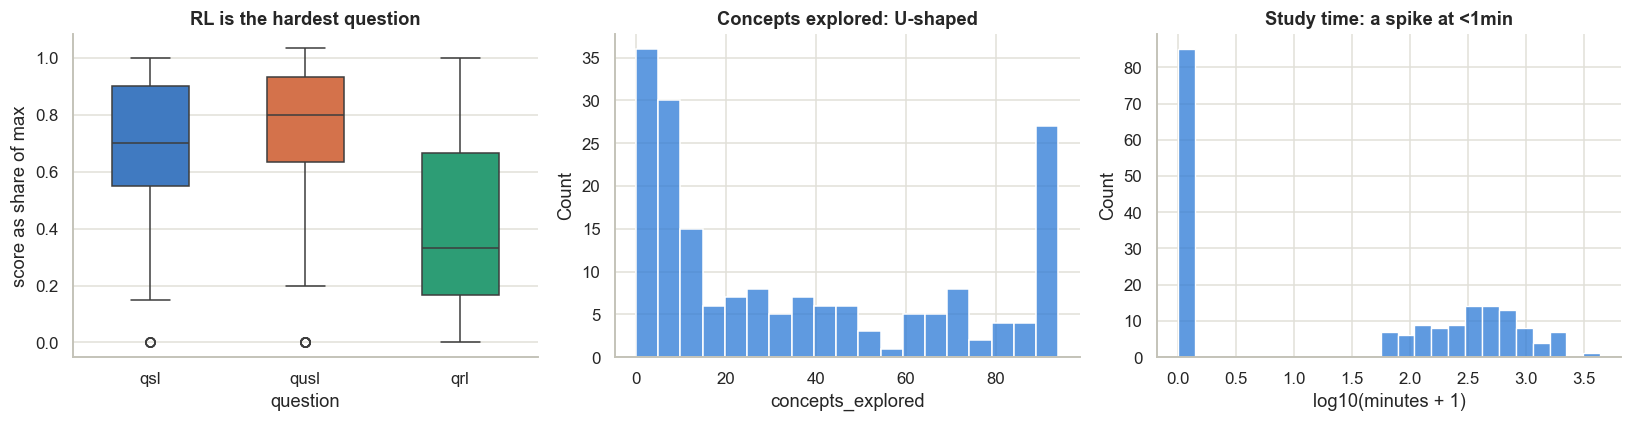

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
shares = raw[list(QUESTIONS)].div(pd.Series(QUESTIONS)).melt(var_name="question", value_name="score as share of max")
sns.boxplot(shares, x="question", y="score as share of max", hue="question", width=0.5, legend=False, ax=axes[0])
sns.histplot(raw, x="concepts_explored", bins=19, ax=axes[1])
sns.histplot(np.log10(raw.minutes + 1), bins=25, ax=axes[2])
axes[0].set_title("RL is the hardest question")
axes[1].set_title("Concepts explored: U-shaped")
axes[2].set(title="Study time: a spike at <1min", xlabel="log10(minutes + 1)")
plt.tight_layout()

- **Scores.** Scaled to their maximum points (4, 3, 3), SL and USL are mostly well answered. RL is clearly harder (median about 1/3 of its points) and is the only question with many zeros. If students differ in *which* topic they fail, RL is the obvious candidate (H3).
- **Concepts explored** is U-shaped: many students barely opened the tool and a block of them explored all 94 concepts. A distribution like this points to distinct engagement groups rather than one continuum (H1).
- **Study time** spans four orders of magnitude (0 to 73 h) with a large spike at `<1min`. A log transform is needed.

### 2.3 Relationships between variables

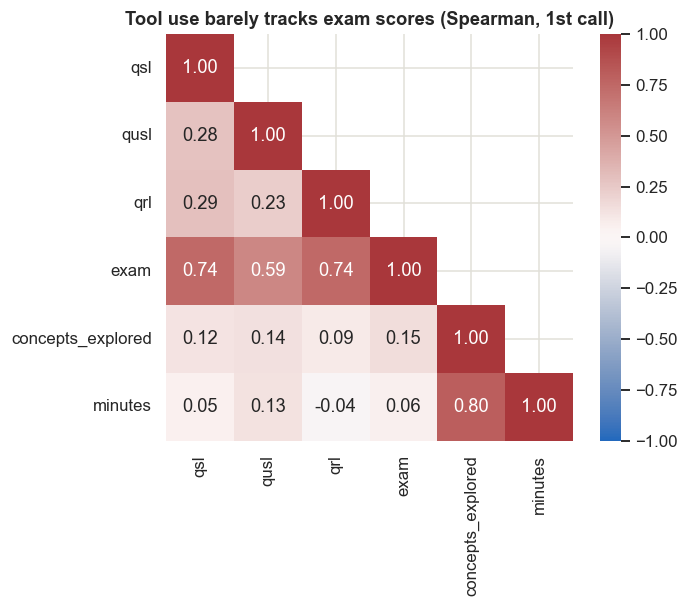

In [5]:
columns = [*QUESTIONS, "exam", "concepts_explored", "minutes"]
correlation = raw.loc[raw.call == "1st", columns].corr(method="spearman")
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)
sns.heatmap(correlation, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
plt.title("Tool use barely tracks exam scores (Spearman, 1st call)");

Spearman correlation is used because the scores are bounded, time spans four orders of magnitude, and both have outliers. Spearman measures any monotonic association and is robust to all three. Two blocks stand out. Concepts explored and minutes are strongly linked (ρ = 0.80), so they form the *engagement* block. The three questions correlate only weakly with each other (ρ = 0.23–0.29), so each carries its own information; together they form the *performance* block. **Between the blocks the correlations are near zero (|ρ| ≤ 0.15).** That is a first warning for H2. The clustering then tests it without assuming the association is monotonic, or even present across the whole range.

### 2.4 First vs. second exam call

In [6]:
raw.groupby("call").agg(
    rows=("uuid", "size"),
    mean_exam=("exam", "mean"),
    pass_rate=("exam", lambda exam: (exam >= PASS_MARK).mean()),
    median_concepts=("concepts_explored", "median"),
    untracked_time=("minutes", lambda minutes: (minutes == 0).mean()),
).round(2)

,rows,mean_exam,pass_rate,median_concepts,untracked_time
call,,,,,
1st,174,6.30,0.76,25.5,0.46
2nd,11,4.05,0.45,9.0,0.45


The 2nd call scores much lower (mean 4.1 vs 6.3, pass rate 45% vs 76%) and its students explored fewer concepts. A naive reading is that the tool matters less in the 2nd call. The audit points the other way: the 2nd call is not a new population: 10 of its 11 students are 1st-call students who **failed** (pass mark assumed at 5/10), trying again. Comparing the two calls as independent groups would therefore be misleading. The right analysis follows each retaker across the two calls (Section 5.2, H4).

## 3. Data Preparation & Feature Selection

- **Merge duplicate logs.** Keep the row with the most concepts for each `(uuid, call)`. The duplicated rows share identical exam scores, so they are snapshots of one student, and a cumulative log can only grow, so the largest is the latest.
- **Drop `exam`, `usage`, `concepts_total` and `study`.** `exam` is a linear combination of the three questions, `usage` is a rounded copy of `breadth`, `concepts_total` has zero variance, and `study` is replaced by numeric `minutes`. Redundant columns would silently double-weight information in a distance.
- **Keep `<1min` students, encoded as 0 minutes.** Dropping them would discard 44% of the students, almost all of the low-use ones, and bias every profile towards engaged students. They are kept, and the profile they form is interpreted with that caveat.
- **breadth = concepts explored / 94.** An exact, unrounded share of the tool explored, in [0, 1].
- **log minutes = log(1 + minutes).** Time is ratio-scaled and right-skewed: going from 1 h to 2 h matters more than going from 30 h to 31 h. Logarithms turn ratios into differences, and the `+1` keeps `<1min` at exactly 0 rather than −∞.
- **Standardise the engagement features.** Breadth and log-minutes have different units. Without scaling, Euclidean distance would be dominated by whichever has the larger variance.
- **Do not standardise question scores; divide by the maximum points instead.** The three shares already share a unit (fraction of the question earned). Standardising would inflate USL, the question with the smallest spread, and distort real differences in difficulty.
- **Euclidean distance.** After these steps, both spaces hold continuous variables on a common scale, so Euclidean distance (the one K-Means, Ward and the Gaussian mixture rely on) is appropriate.
- **Two separate feature spaces.** If engagement and performance shared one distance, any association between them would partly be *built into* the clusters, making H2 circular. Separate spaces keep the test honest.
- **Fit on the 1st call only.** The 2nd call repeats 10 of the same people, which would count them twice. It is used as an out-of-sample projection for H4.

In [7]:
def prepare(raw):
    # keep the latest (largest) cumulative log per student and call
    frame = (raw.sort_values("concepts_explored")
                .drop_duplicates(["uuid", "call"], keep="last")
                .assign(breadth=lambda d: d.concepts_explored / d.concepts_total,
                        log_minutes=lambda d: np.log1p(d.minutes),
                        passed=lambda d: d.exam >= PASS_MARK))
    for question, points in QUESTIONS.items():
        frame[f"{question}_share"] = frame[question] / points
    return frame.drop(columns=["usage", "concepts_total", "study"]).reset_index(drop=True)


students = prepare(raw)
first = students[students.call == "1st"].reset_index(drop=True)
second = students[students.call == "2nd"].reset_index(drop=True)

ENGAGEMENT = ["breadth", "log_minutes"]
PERFORMANCE = ["qsl_share", "qusl_share", "qrl_share"]
engagement_scaler = StandardScaler().fit(first[ENGAGEMENT])
X_engagement = engagement_scaler.transform(first[ENGAGEMENT])
X_performance = first[PERFORMANCE].to_numpy()
print(f"{len(first)} unique 1st-call students, {len(second)} 2nd-call students")

167 unique 1st-call students, 11 2nd-call students


## 4. Clustering Analysis & Evaluation

### 4.1 Choosing *k*: four criteria together

Silhouette alone is fragile on 167 students, so four signals are read together for every *k*:

1. **Elbow** of the K-Means inertia.
2. **Silhouette**, read against the course scale (< 0.25 no structure · 0.25–0.5 weak, probably artificial · 0.5–0.7 reasonable · > 0.7 strong) **and against a null baseline**: the same algorithm run on data where every column is shuffled on its own. That keeps each variable's distribution but destroys any joint structure. A silhouette that does not beat its null only reflects the shape of the variables, not real groups.
3. **Davies–Bouldin index** (lower is better).
4. **Bootstrap stability**: refit on 100 resamples and compare each result to the full-data partition with the adjusted Rand index (ARI). Real clusters survive resampling.

**Hyperparameters**

- **K-Means:** k-means++ initialisation with `n_init = 20` restarts, keeping the lowest-inertia solution, so a result never depends on one unlucky start. `random_state` is fixed so every number in this report is reproducible.
- **EM (Gaussian mixture):** full covariance matrices with 10 restarts, so clusters may be elliptical and of different sizes, which is exactly the case K-Means cannot model.
- **Agglomerative:** Ward linkage (it minimises within-cluster variance, the hierarchical counterpart of K-Means), plus complete, average and single linkage from the slides for comparison.
- **Evaluation:** 100 bootstrap resamples and 10 column shuffles per *k*, and 5,000 permutations for the test in H2 (p-value resolution 0.0002).
- **DBSCAN:** `eps` and `min_samples` are justified in Section 4.3.

In [8]:
def kmeans(X, k, seed=SEED):
    return KMeans(k, n_init=20, random_state=seed).fit(X)


def shuffled(X):
    # null model: keeps each feature's distribution, destroys the joint structure
    return np.column_stack([rng.permutation(column) for column in X.T])


def stability(X, k, n_boot=100):
    # mean ARI between the full-data partition and refits on bootstrap resamples
    reference = kmeans(X, k).labels_
    scores = []
    for b in range(n_boot):
        sample = rng.integers(0, len(X), len(X))
        scores.append(adjusted_rand_score(reference, kmeans(X[sample], k, seed=b).predict(X)))
    return np.mean(scores)


def scan_k(X, ks=range(2, 9), n_null=10):
    rows = []
    for k in ks:
        model = kmeans(X, k)
        null = [silhouette_score(Xn, kmeans(Xn, k).labels_) for Xn in (shuffled(X) for _ in range(n_null))]
        rows.append({"k": k, "inertia": model.inertia_,
                     "silhouette": silhouette_score(X, model.labels_), "silhouette (null)": np.mean(null),
                     "davies-bouldin": davies_bouldin_score(X, model.labels_), "stability (ARI)": stability(X, k)})
    return pd.DataFrame(rows).set_index("k").round(3)


def plot_scan(scan, title):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
    scan.inertia.plot(ax=axes[0], marker="o", title="Elbow (inertia)")
    scan[["silhouette", "silhouette (null)"]].plot(ax=axes[1], marker="o", style=["-", "--"], title="Silhouette vs null")
    for threshold in (0.25, 0.5, 0.7):
        axes[1].axhline(threshold, color="#c3c2b7", lw=0.8, ls=":")
    scan["davies-bouldin"].plot(ax=axes[2], marker="o", title="Davies–Bouldin (lower is better)")
    scan["stability (ARI)"].plot(ax=axes[3], marker="o", title="Bootstrap stability", ylim=(0, 1.05))
    fig.suptitle(title, fontweight="bold", y=1.04)

,inertia,silhouette,silhouette (null),davies-bouldin,stability (ARI)
k,,,,,
2,87.533,0.662,0.499,0.473,0.974
3,33.413,0.691,0.565,0.498,0.994
4,24.709,0.675,0.654,0.540,0.872
5,17.945,0.611,0.615,0.670,0.864
6,13.727,0.591,0.597,0.720,0.919
7,11.534,0.565,0.574,0.645,0.887
8,9.650,0.562,0.566,0.639,0.876


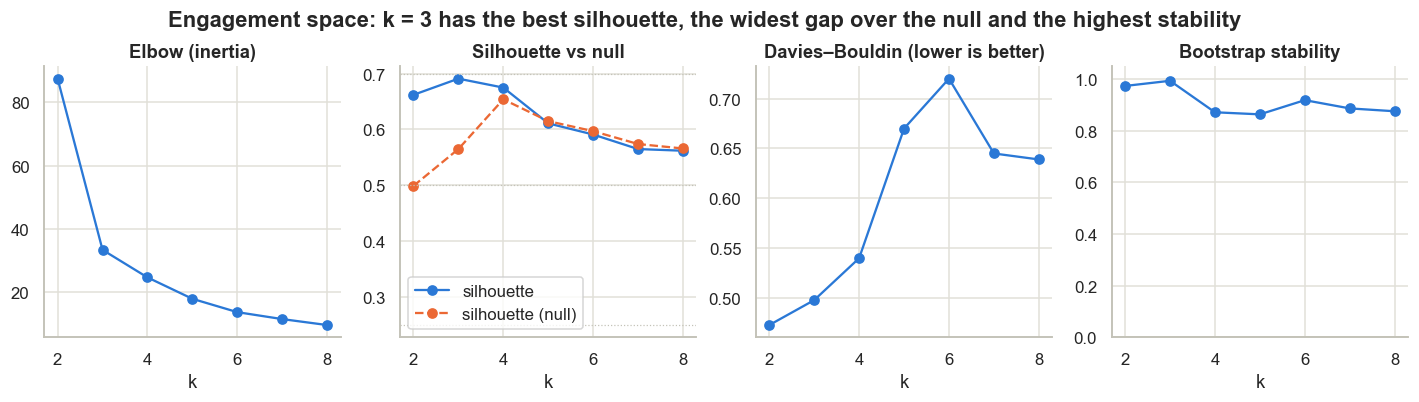

In [9]:
engagement_scan = scan_k(X_engagement)
plot_scan(engagement_scan, "Engagement space: k = 3 has the best silhouette, the widest gap over the null and the highest stability")
engagement_scan

**k = 3** is the clear choice for engagement. It has the highest silhouette (≈ 0.69, the top of the course's "reasonably well-defined" band), clearly above its shuffled null (≈ 0.57). It is almost perfectly stable (ARI ≈ 0.99), sits at the elbow of the inertia curve, and keeps Davies–Bouldin close to its minimum (reached at k = 2). From k = 4 the gap over the null almost vanishes, and from k = 5 it is gone.

### 4.2 Do different algorithms agree?

A partition that only one algorithm finds says more about that algorithm than about the data. The course algorithms are run at the chosen *k* and compared pairwise with ARI.

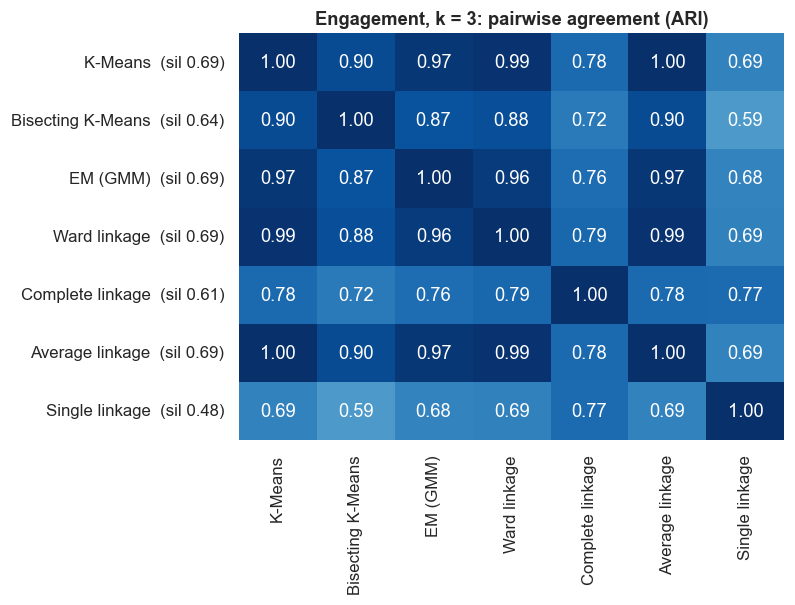

In [10]:
def cluster_all(X, k):
    return pd.DataFrame({
        "K-Means": kmeans(X, k).labels_,
        "Bisecting K-Means": BisectingKMeans(k, n_init=10, random_state=SEED).fit_predict(X),
        "EM (GMM)": GaussianMixture(k, n_init=10, random_state=SEED).fit(X).predict(X),
        **{f"{linkage.title()} linkage": AgglomerativeClustering(k, linkage=linkage).fit_predict(X)
           for linkage in ["ward", "complete", "average", "single"]},
    })


def plot_agreement(X, k, title):
    labels = cluster_all(X, k)
    ari = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in labels] for a in labels],
                       index=labels.columns, columns=labels.columns)
    silhouettes = labels.apply(lambda column: silhouette_score(X, column)).round(2)
    ari.index = [f"{name}  (sil {silhouettes[name]:.2f})" for name in ari.index]
    sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False)
    plt.title(title)


plot_agreement(X_engagement, 3, "Engagement, k = 3: pairwise agreement (ARI)")

K-Means, bisecting K-Means, EM, Ward and average linkage largely agree (ARI 0.87–1.00), so the three profiles do not depend on the choice of algorithm. Complete and especially single linkage drift away, as the course slides predict: single linkage chains through the sparse middle of the space, and complete linkage favours equal-diameter groups, so neither suits clusters of very different spread.

### 4.3 DBSCAN as an anomaly detector

DBSCAN does not need *k*. Here it is used for what it does best: flagging students who sit in low-density regions. `min_samples = 5` follows the usual rule of thumb (at least twice the number of features, here 2 × 2 = 4, rounded up for a small and noisy sample), and `eps` is read from the knee of the sorted distances to each student's 4th nearest neighbour (5 points including itself, matching `min_samples`).

K-Means agreement with vs. without the anomalies: ARI = 0.985


,uuid,concepts_explored,minutes,exam
82,d79a695e,27,4393,6.00
98,8019336c,40,2045,5.20
112,059e787b,55,0,6.80
123,61b1b9b3,70,0,7.70
125,09822357,71,0,6.95


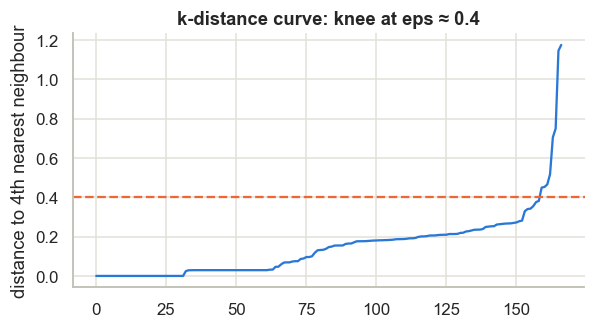

In [11]:
distances = np.sort(NearestNeighbors(n_neighbors=5).fit(X_engagement).kneighbors(X_engagement)[0][:, -1])
plt.figure(figsize=(6, 3))
plt.plot(distances)
plt.axhline(0.4, color=PALETTE[1], ls="--")
plt.title("k-distance curve: knee at eps ≈ 0.4")
plt.ylabel("distance to 4th nearest neighbour")

first["anomaly"] = DBSCAN(eps=0.4, min_samples=5).fit_predict(X_engagement) == -1
kept = ~first.anomaly.to_numpy()
refit = kmeans(StandardScaler().fit_transform(first.loc[kept, ENGAGEMENT]), 3).labels_
print(f"K-Means agreement with vs. without the anomalies: ARI = {adjusted_rand_score(kmeans(X_engagement, 3).labels_[kept], refit):.3f}")
first.loc[first.anomaly, ["uuid", "concepts_explored", "minutes", "exam"]].assign(uuid=lambda d: d.uuid.str[:8])

DBSCAN independently confirms the audit. Its noise points are the students with **55–71 concepts in under a minute** (impossible logs) and the two with **34 h and 73 h of study** (extreme time). They are kept in the analysis, since refitting K-Means without them changes the cluster of only one of the remaining students (ARI ≈ 0.99), but they are marked on the engagement map and treated with caution.

### 4.4 Final engagement profiles

Clusters are renumbered by increasing breadth, so their names do not depend on the random seed.

In [12]:
ENGAGEMENT_PROFILES = ["Ghosts", "Samplers", "Completionists"]
PERFORMANCE_PROFILES = ["RL-gap", "All-rounders"]


def namer(labels, order_by, names):
    # rank clusters by a variable so their names do not depend on the seed
    rank = pd.Series(order_by).groupby(labels).mean().rank().astype(int) - 1
    return lambda new_labels: pd.Categorical([names[rank[label]] for label in new_labels], categories=names)


def profile(frame, by):
    return frame.groupby(by, observed=True).agg(
        students=("uuid", "size"), median_concepts=("concepts_explored", "median"),
        median_hours=("minutes", lambda minutes: minutes.median() / 60),
        untracked=("minutes", lambda minutes: (minutes == 0).mean()),
        sl=("qsl_share", "mean"), usl=("qusl_share", "mean"), rl=("qrl_share", "mean"),
        exam=("exam", "mean"), pass_rate=("passed", "mean")).round(2)


engagement_model = kmeans(X_engagement, 3)
engagement_name = namer(engagement_model.labels_, first.breadth, ENGAGEMENT_PROFILES)
first["engagement"] = engagement_name(engagement_model.labels_)
second["engagement"] = engagement_name(engagement_model.predict(engagement_scaler.transform(second[ENGAGEMENT])))
profile(first, "engagement")

,students,median_concepts,median_hours,untracked,sl,usl,rl,exam,pass_rate
engagement,,,,,,,,,
Ghosts,73,7.0,0.00,1.0,0.68,0.74,0.43,6.23,0.73
Samplers,42,33.0,3.62,0.0,0.69,0.73,0.38,6.08,0.71
Completionists,52,89.5,9.50,0.0,0.73,0.81,0.43,6.62,0.83


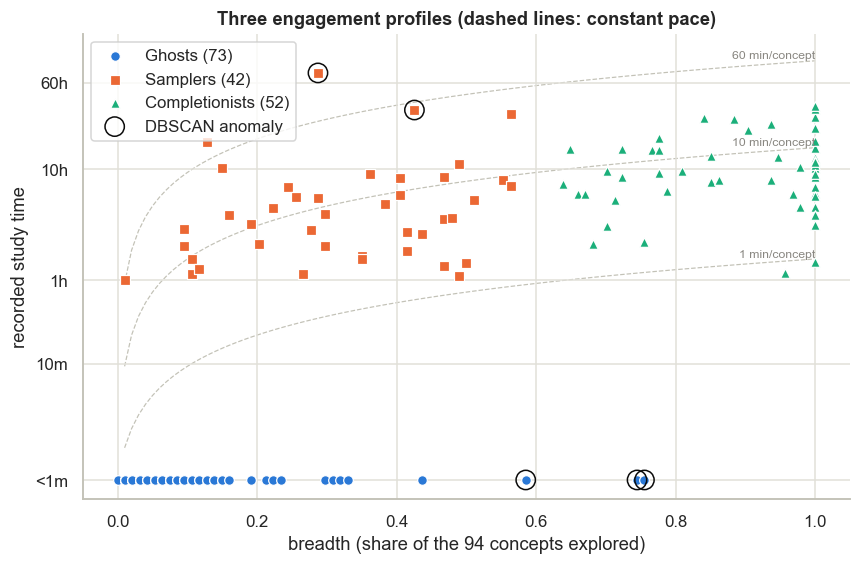

In [13]:
TIME_TICKS = {"<1m": 0, "10m": 10, "1h": 60, "10h": 600, "60h": 3600}


def engagement_axes(ax):
    breadth = np.linspace(0.01, 1, 100)
    for pace in (1, 10, 60):
        ax.plot(breadth, np.log1p(pace * 94 * breadth), color="#c3c2b7", lw=0.8, ls="--", zorder=0)
        ax.annotate(f"{pace} min/concept", (1, np.log1p(pace * 94)), color="#898781", fontsize=8, ha="right", va="bottom")
    ax.set_yticks(np.log1p(list(TIME_TICKS.values())), TIME_TICKS.keys())
    ax.set(xlabel="breadth (share of the 94 concepts explored)", ylabel="recorded study time", ylim=(-0.4, 9.2))


def engagement_map(ax, frame, hue, names):
    for i, name in enumerate(names):
        group = frame[frame[hue] == name]
        ax.scatter(group.breadth, group.log_minutes, s=40, color=PALETTE[i], marker=MARKERS[i],
                   edgecolor="white", linewidth=0.8, label=f"{name} ({len(group)})")
    engagement_axes(ax)


fig, ax = plt.subplots(figsize=(9, 5.5))
engagement_map(ax, first, "engagement", ENGAGEMENT_PROFILES)
ax.scatter(*first.loc[first.anomaly, ENGAGEMENT].T.values, s=160, facecolor="none", edgecolor="#0b0b0b", lw=1, label="DBSCAN anomaly")
ax.legend(loc="upper left")
ax.set_title("Three engagement profiles (dashed lines: constant pace)");

- **Ghosts:** no recorded study time and a handful of concepts (median 7 of 94). They barely opened the tool, or they browsed it without the tracker counting time.
- **Samplers:** explored about a third of the tool over a few hours.
- **Completionists:** explored nearly all 94 concepts and logged many hours.

**Is pace a profile of its own? (second half of H1).** The dashed lines mark constant minutes per concept, so pace is the *diagonal* direction of this map. To test whether pace forms profiles independently of volume, the same model-selection procedure is repeated on the 94 students with recorded time, using breadth and log(minutes per concept). Students without recorded time are excluded here because their pace is undefined.

,inertia,silhouette,silhouette (null),davies-bouldin,stability (ARI)
k,,,,,
2,107.708,0.405,0.409,0.987,0.739
3,71.207,0.429,0.395,0.864,0.736
4,52.326,0.407,0.412,0.810,0.656
5,38.001,0.419,0.400,0.753,0.660
6,29.466,0.418,0.386,0.750,0.688
7,23.710,0.429,0.397,0.667,0.734
8,21.047,0.407,0.387,0.754,0.654


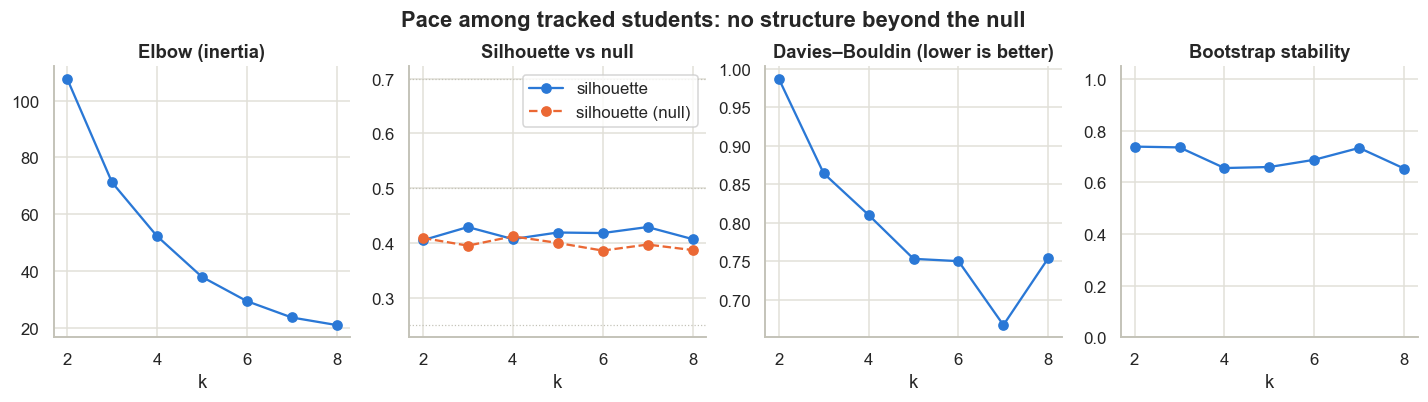

In [14]:
tracked = first[first.minutes > 0]
X_pace = StandardScaler().fit_transform(np.column_stack([tracked.breadth, np.log(tracked.minutes / tracked.concepts_explored)]))
pace_scan = scan_k(X_pace)
plot_scan(pace_scan, "Pace among tracked students: no structure beyond the null")
pace_scan

At no *k* does the pace silhouette (0.41–0.43) clearly beat its shuffled null (0.39–0.41; at k = 2 and k = 4 it is even below it), and stability is mediocre (ARI 0.65–0.74). **Pace varies continuously.** There are no "fast skimmers" and "slow deep-divers" as separate groups, only students spread along a continuum.

### 4.5 Exam-performance profiles

,inertia,silhouette,silhouette (null),davies-bouldin,stability (ARI)
k,,,,,
2,18.845,0.373,0.357,1.061,0.934
3,15.232,0.290,0.307,1.221,0.707
4,12.545,0.286,0.299,1.229,0.612
5,10.785,0.292,0.284,1.095,0.581
6,9.195,0.305,0.282,1.008,0.586
7,8.238,0.284,0.289,1.038,0.577
8,7.204,0.301,0.288,0.986,0.612


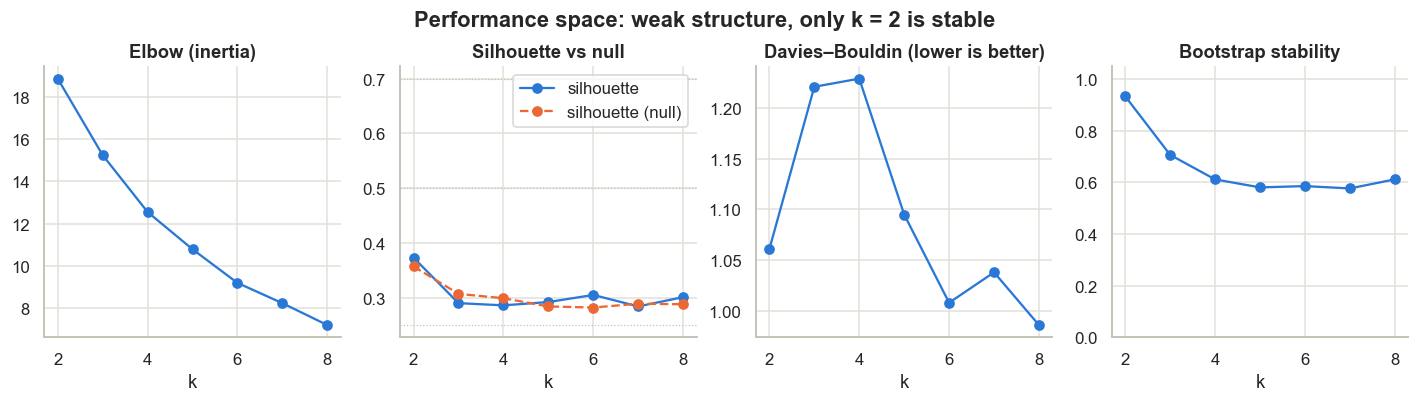

In [15]:
performance_scan = scan_k(X_performance)
plot_scan(performance_scan, "Performance space: weak structure, only k = 2 is stable")
performance_scan

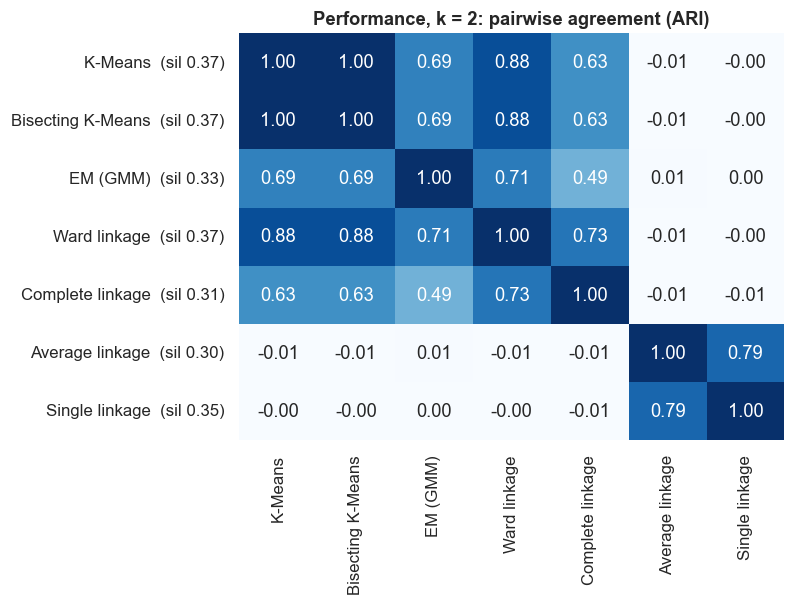

In [16]:
plot_agreement(X_performance, 2, "Performance, k = 2: pairwise agreement (ARI)")

Performance has much weaker structure. The silhouette peaks at k = 2 (≈ 0.37, the "weak" band) and barely beats its null (≈ 0.35). From k = 3 onwards the silhouette stays level with its null (within ±0.03) and the partitions become unstable (ARI 0.58–0.71). Only **k = 2** is stable (ARI ≈ 0.93) and reproduced by K-Means, bisecting K-Means and Ward (ARI 0.88–1.00). Average and single linkage only split off a few outlying students, which is the typical failure of these linkages on continuous data. Exam scores are therefore closer to a continuum cut into two halves than to natural groups, and they are interpreted with that in mind.

In [17]:
performance_model = kmeans(X_performance, 2)
first["performance"] = namer(performance_model.labels_, first[PERFORMANCE].mean(axis=1), PERFORMANCE_PROFILES)(performance_model.labels_)
profile(first, "performance")

,students,median_concepts,median_hours,untracked,sl,usl,rl,exam,pass_rate
performance,,,,,,,,,
RL-gap,92,21.5,1.46,0.43,0.64,0.71,0.17,5.21,0.58
All-rounders,75,30.0,1.67,0.44,0.77,0.82,0.72,7.67,0.97


## 5. Interpretation & Final Report

### 5.1 Cluster interpretation

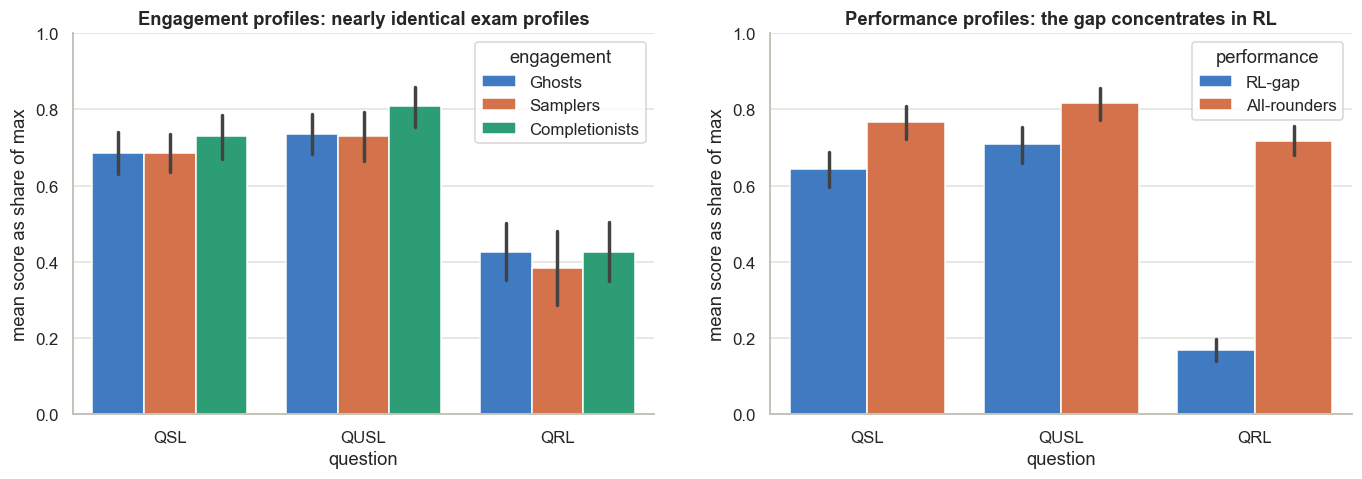

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (hue, names) in zip(axes, [("engagement", ENGAGEMENT_PROFILES), ("performance", PERFORMANCE_PROFILES)]):
    shares = first.melt(id_vars=hue, value_vars=PERFORMANCE, var_name="question", value_name="share")
    shares["question"] = shares.question.str.removesuffix("_share").str.upper()
    sns.barplot(shares, x="question", y="share", hue=hue, hue_order=names, palette=PALETTE[:len(names)], errorbar=("ci", 95), ax=ax)
    ax.set(ylim=(0, 1), ylabel="mean score as share of max")
axes[0].set_title("Engagement profiles: nearly identical exam profiles")
axes[1].set_title("Performance profiles: the gap concentrates in RL");

**Engagement profiles**, from the profile table and the left chart:

- **Ghosts:** 44% of students. No recorded time, median 7 concepts.
- **Samplers:** 25%. Median 33 concepts over about 3.6 hours.
- **Completionists:** 31%. Median 90 concepts over about 9.5 hours.

All three have almost the same exam profile: means of 6.1–6.6 out of 10 and pass rates of 71–83%, with overlapping confidence intervals on every question.

**Performance profiles**, from the right chart:

- **All-rounders** (45%) are strong and *balanced*: 72–82% of the points on every question, and a 97% pass rate.
- **RL-gap** students (55%) are not uniformly weaker. They keep a respectable 64% on SL and 71% on USL but earn only **17% on RL**, with a 58% pass rate.

The low group is defined by *what* it gets wrong, not only by *how much*. Section 5.2 quantifies this.

### 5.2 Hypothesis testing

#### H1: Engagement profiles

**Partially supported.** In the volume of use (breadth × time) there are three profiles. They are stable (ARI ≈ 0.99), reasonably well defined on the course scale (silhouette ≈ 0.69), clearly above the shuffled null and reproduced by five of the seven algorithms. Pace, however, does not form profiles: among tracked students its structure is no better than shuffled data. Students differ in *how much* they use the tool, not in *how fast*. One caveat: part of the Ghosts' separation comes from the `<1min` floor, so that profile mixes genuine low use with untracked time.

#### H2: Decoupling of engagement and performance

Kruskal–Wallis on total exam score across engagement profiles: H = 2.03, p = 0.36


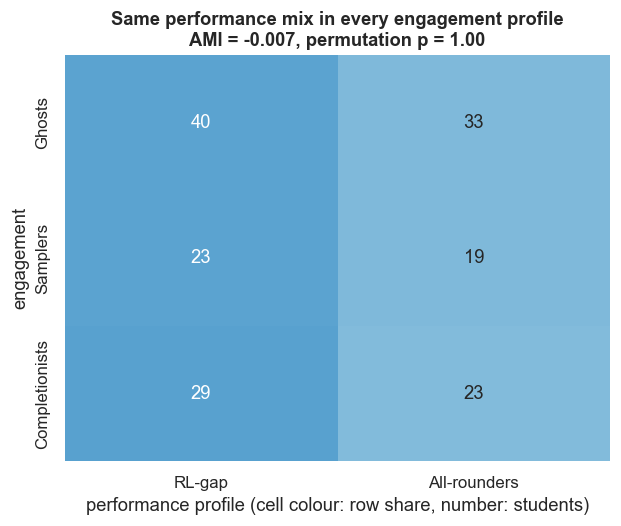

In [19]:
def permutation_ami(a, b, n=5000):
    # p-value: share of label shufflings that agree at least as well as the real labels
    observed = adjusted_mutual_info_score(a, b)
    null = np.array([adjusted_mutual_info_score(a, rng.permutation(b)) for _ in range(n)])
    return observed, (np.sum(null >= observed) + 1) / (n + 1)


ami, p_value = permutation_ami(first.engagement, first.performance)
h_stat, p_kruskal = kruskal(*[group.exam for _, group in first.groupby("engagement", observed=True)])

counts = pd.crosstab(first.engagement, first.performance)
sns.heatmap(counts.div(counts.sum(axis=1), axis=0), annot=counts, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False)
plt.title(f"Same performance mix in every engagement profile\nAMI = {ami:.3f}, permutation p = {p_value:.2f}")
plt.xlabel("performance profile (cell colour: row share, number: students)")
print(f"Kruskal–Wallis on total exam score across engagement profiles: H = {h_stat:.2f}, p = {p_kruskal:.2f}")

**Supported.** The two maps are statistically independent. AMI is slightly *below* zero, its chance level, so practically every random relabelling of the students agrees at least as well as the real one (p ≈ 1). Every engagement profile has the same RL-gap / All-rounder mix, and a non-parametric test on the total exam score finds no difference between profiles either. Put the other way round, students with the same exam profile used the tool in completely different ways, so the brief's third suggested hypothesis also holds.

#### H3: Level vs. shape of exam profiles

Each student's score vector $x_i$ (shares of the three questions) splits exactly into a **level** $\ell_i = \bar{x}_i$ and a **shape** $s_i = x_i - \ell_i\mathbf{1}$. Because $s_i \perp \mathbf{1}$, the same split holds for cluster means, so the between-cluster sum of squares divides exactly:

$$B = \sum_c n_c\lVert \bar{x}_c - \bar{x}\rVert^2 = \underbrace{3\sum_c n_c(\bar{\ell}_c - \bar{\ell})^2}_{\text{level}} + \underbrace{\sum_c n_c\lVert \bar{s}_c - \bar{s}\rVert^2}_{\text{shape}}$$

A partition driven only by ability would have a shape share near 0. Shape is closely related to the course's correlation dissimilarity, which also removes each profile's level (and, in addition, its spread) and compares only its form.

In [20]:
def between_ss(M, labels):
    # with one group per student this is the total sum of squares
    centroids = pd.DataFrame(M).groupby(labels, observed=True).transform("mean").to_numpy()
    return ((centroids - M.mean(axis=0)) ** 2).sum(axis=0)


def level_shape_shares(labels):
    b_level = X_performance.shape[1] * between_ss(level, labels).sum()
    b_shape = between_ss(shape, labels)
    return pd.Series([b_level, *b_shape], index=["level", *(f"shape · {q.upper()}" for q in QUESTIONS)]) / (b_level + b_shape.sum())


level = X_performance.mean(axis=1, keepdims=True)
shape = X_performance - level
pd.DataFrame({"across students (total SS)": level_shape_shares(np.arange(len(first))),
              "between the two profiles": level_shape_shares(first.performance)}).round(3)

,across students (total SS),between the two profiles
level,0.492,0.617
shape · QSL,0.143,0.057
shape · QUSL,0.156,0.071
shape · QRL,0.210,0.255


**Supported.** Across individual students, level and shape carry about the same variance (49% vs 51%). Between the two profiles, level dominates (62%), but shape still explains 38% of the separation, and two thirds of that comes from the RL component alone (26% of the total, against 6–7% each for SL and USL). The low group's deficit is concentrated in RL far more than in SL or USL. In practice, the exam's main dividing line is the reinforcement-learning question. (Since the clusters were built on these same scores, this is a description of the partition, not an independent test. See Limitations.)

#### H4: The second call as a retake population

In [21]:
retakers = first.merge(second, on="uuid", suffixes=("_1st", "_2nd"))
# minutes may differ by 1 between snapshots because of rounding
retakers["same_log"] = (retakers.concepts_explored_1st == retakers.concepts_explored_2nd) & ((retakers.minutes_1st - retakers.minutes_2nd).abs() <= 1)
retakers[["uuid", "engagement_1st", "engagement_2nd", "exam_1st", "exam_2nd", "concepts_explored_1st", "concepts_explored_2nd", "same_log"]].assign(uuid=lambda d: d.uuid.str[:8]).sort_values("exam_2nd")

,uuid,engagement_1st,engagement_2nd,exam_1st,exam_2nd,concepts_explored_1st,concepts_explored_2nd,same_log
0,980a3c76,Samplers,Samplers,2.6,0.0,1,1,True
7,576f34c5,Ghosts,Ghosts,2.7,0.0,22,22,True
2,6c584f67,Ghosts,Ghosts,1.8,1.7,2,2,True
3,410354a9,Ghosts,Ghosts,1.2,2.0,4,4,True
9,f89de580,Samplers,Samplers,2.2,3.8,46,46,True
8,e43b51cb,Samplers,Samplers,3.3,4.6,39,39,True
4,0bf9acef,Ghosts,Ghosts,3.2,5.4,9,9,True
5,951320f9,Samplers,Completionists,3.8,6.6,12,94,False
6,67ac5518,Samplers,Samplers,3.3,6.9,19,19,True
1,07fbf207,Ghosts,Ghosts,3.4,7.3,1,1,True


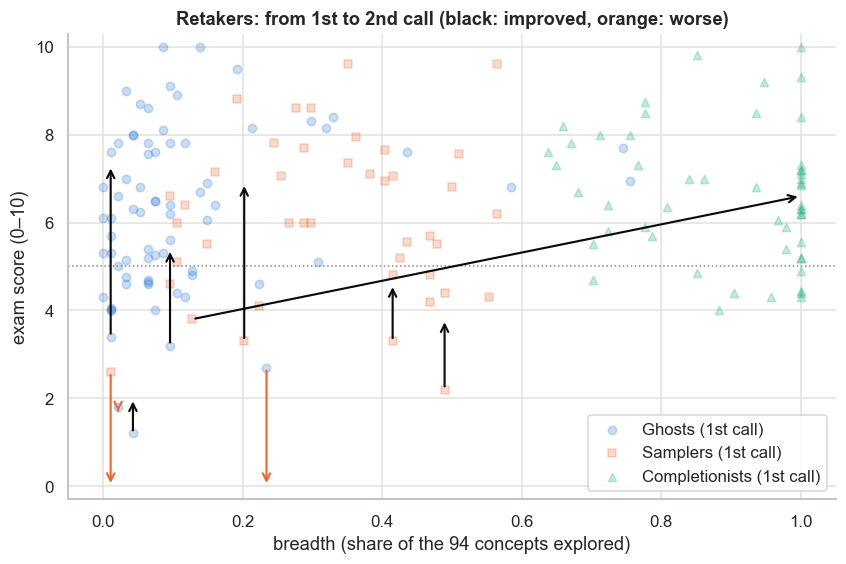

In [22]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, name in enumerate(ENGAGEMENT_PROFILES):
    group = first[first.engagement == name]
    ax.scatter(group.breadth, group.exam, s=30, color=PALETTE[i], marker=MARKERS[i], alpha=0.25, label=f"{name} (1st call)")
for _, r in retakers.iterrows():
    ax.annotate("", (r.breadth_2nd, r.exam_2nd), (r.breadth_1st, r.exam_1st),
                arrowprops={"arrowstyle": "->", "color": "#0b0b0b" if r.exam_2nd >= r.exam_1st else PALETTE[1], "lw": 1.4})
ax.axhline(PASS_MARK, color="#898781", ls=":", lw=1)
ax.set(xlabel="breadth (share of the 94 concepts explored)", ylabel="exam score (0–10)", ylim=(-0.3, 10.3),
       title="Retakers: from 1st to 2nd call (black: improved, orange: worse)")
ax.legend(loc="lower right");

In [23]:
for label, group in [("the rest of the 1st call", first), ("the other failing students", first[~first.passed])]:
    table = pd.crosstab(group.uuid.isin(second.uuid), group.engagement == "Completionists")
    print(f"Completionists among retakers {table.loc[True, True]}/{table.loc[True].sum()} vs. {label} "
          f"{table.loc[False, True]}/{table.loc[False].sum()}: Fisher p = {fisher_exact(table)[1]:.3f}")
print(f"Retakers with an unchanged tool log: {retakers.same_log.sum()} / {len(retakers)}")
print(f"Retakers who improved: {(retakers.exam_2nd > retakers.exam_1st).sum()} / {len(retakers)}, passed: {retakers.passed_2nd.sum()}")

Completionists among retakers 0/10 vs. the rest of the 1st call 52/157: Fisher p = 0.032
Completionists among retakers 0/10 vs. the other failing students 9/31: Fisher p = 0.083
Retakers with an unchanged tool log: 9 / 10
Retakers who improved: 7 / 10, passed: 4


**Mostly supported, with small numbers.**

- **Where retakers come from.** None of the 10 retakers is a Completionist, against 52 of the other 157 1st-call students (Fisher p = 0.03). Compared with the *other failing students*, though, the difference (0/10 vs 9/31) does not reach significance (p = 0.08). Retakers look like the other failing students; what sets them apart from the 1st call as a whole is mainly that they failed.
- **Their tool use did not change.** 9 of 10 retakers have an identical tool log in both calls. The one exception went from 12 to 94 concepts and from 3.8 to 6.6.
- **Their results still moved.** 7 of 10 improved and 4 passed, almost all with no further tool use, so whatever was behind those changes does not show up in the tool's logs. Two retakers scored exactly 0 on all three questions in the 2nd call, which looks like a blank submission or a no-show rather than a measured result.
- **Does the tool-use/score relationship differ between calls?** (the brief's fourth suggestion) Eleven 2nd-call students are far too few to cluster on their own. Following the same students across both calls, as done here, is the analysable version of that question.

### 5.3 Final report

**Approach.** The 1st-call students (n = 167 after merging duplicate log snapshots) were clustered twice: on *how they used the tool* (breadth and log study time, standardised) and on *how they did on the exam* (each question as a share of its maximum). For every *k*, the choice combined the elbow, silhouette (read against the course scale and against a column-shuffled null), Davies–Bouldin and bootstrap stability. Seven clustering algorithms and linkages from the course were cross-checked, and DBSCAN was used to flag anomalous logs. The 2nd call was treated as a linked retake cohort, not as an independent sample.

**Final clusters.**

- **Engagement (k = 3):** *Ghosts* (44%, no recorded time), *Samplers* (25%, about a third of the tool) and *Completionists* (31%, nearly all of it). Silhouette 0.69, stability 0.99.
- **Performance (k = 2):** *All-rounders* (45%, balanced and strong) and *RL-gap* students (55%, 17% of the RL points against 72% for All-rounders). The structure is weak but stable.

**Answers.**

- **H1 · Partially supported.** There are three robust profiles of *volume* of use, but *pace* is a continuum (its silhouette is no better than the null).
- **H2 · Supported.** AMI = −0.007, permutation p ≈ 1, Kruskal–Wallis p = 0.36: every engagement profile has the same performance mix.
- **H3 · Supported.** Shape accounts for 38% of the between-cluster separation, two thirds of it from RL.
- **H4 · Mostly supported.** No retaker is a Completionist (p = 0.03 against the rest of the 1st call) and 9/10 never changed their tool use, but against the other failing students the difference is not significant (p = 0.08, n = 10).

**Main takeaway.** How much students used the tool tells us nothing about how they did on the exam. What separates students on the exam is one topic, reinforcement learning, and that gap appears in every engagement profile.

**Limitations.**

- **Observational data, no causal claims.** "Tool use is unrelated to scores" does not mean "the tool is useless". For example, weaker students might use it to catch up while stronger students use it out of interest, and the two effects could cancel out. Nothing here identifies the tool's effect.
- **Unreliable time.** 44% of 1st-call students have `<1min` recorded, including impossible logs. The Ghosts profile therefore mixes genuine non-use with tracking failure, and the pace analysis covers only tracked students.
- **Small samples and self-selection.** 167 students limit how fine the profiles can be. H4 rests on 10 retakers who chose to sit the exam again, so it is descriptive.
- **Weak performance structure.** Exam scores are close to a continuum, so the two performance profiles are a stable *summary*, not natural kinds.
- **Circularity in H3.** Clusters are described with the same features used to build them, so the level/shape split characterises the partition rather than testing it independently.
- **Unknown timing.** The data does not say whether the tool was used before or after each exam, and the pass mark of 5/10 is an assumption.
- **Algorithm assumptions.** K-Means favours compact, roughly spherical clusters. Agreement with GMM and Ward reduces, but does not remove, this dependence.